# Détection d’activités d’oiseaux dans des enregistrements audio par réseaux de neurones frugaux


## 0 - Télécharger les données audio

Soit en les téléchargeant et décompressant depuis les liens suivants :
- files.zip (153 ko) : https://uncloud.univ-nantes.fr/index.php/s/wyw9sZT3AMD3fCs -> fichiers du git, pour les deux parties
- examples.zip (4.2 Mo) : https://uncloud.univ-nantes.fr/index.php/s/6XQPXKQ8Syyq3Xb -> pour les deux parties
- dataset.zip (1.1 Go) : https://uncloud.univ-nantes.fr/index.php/s/CEjynZsiXAX8P8g -> pour la seconde partie

Soit en lançant la cellule suivante :


In [1]:
import zipfile, urllib.request

# Tétécharger les fichiers du git (pour les deux parties)
'''
import shutil
from pathlib import Path

# files.zip : https://uncloud.univ-nantes.fr/index.php/s/wyw9sZT3AMD3fCs
url = "https://uncloud.univ-nantes.fr/public.php/dav/files/wyw9sZT3AMD3fCs/?accept=zip"
urllib.request.urlretrieve(url, "files.zip")
with zipfile.ZipFile("files.zip") as z:
    z.extractall("")

for item in Path("files").iterdir():
    shutil.move(str(item), ".")
Path("files").rmdir()
'''

# examples.zip : https://uncloud.univ-nantes.fr/index.php/s/6XQPXKQ8Syyq3Xb -> pour les deux parties
'''
url = "https://uncloud.univ-nantes.fr/public.php/dav/files/6XQPXKQ8Syyq3Xb/?accept=zip"  
urllib.request.urlretrieve(url, "examples.zip")
with zipfile.ZipFile("examples.zip") as z:
    z.extractall("data")
'''

# dataset.zip : https://uncloud.univ-nantes.fr/index.php/s/CEjynZsiXAX8P8g -> pour la partie 2
'''
url = "https://uncloud.univ-nantes.fr/public.php/dav/files/CEjynZsiXAX8P8g/?accept=zip" 
urllib.request.urlretrieve(url, "dataset.zip")
with zipfile.ZipFile("dataset.zip") as z:
    z.extractall("data")
'''


'\nurl = "https://uncloud.univ-nantes.fr/public.php/dav/files/CEjynZsiXAX8P8g/?accept=zip" \nurllib.request.urlretrieve(url, "dataset.zip")\nwith zipfile.ZipFile("dataset.zip") as z:\n    z.extractall("data")\n'

# 1 - Représentation temps-fréquence

In [2]:
import os
import IPython
import matplotlib.pyplot as plt

import torchaudio
import librosa
import numpy as np

from src.utils import plot_mel_spec

## 1.1 - Lire une forme d'onde

In [ ]:
# Lecture du fichier
base_dir = "data/examples"
fname = "DENMAJ_D_XC704957_t15.wav"
wav_path = os.path.join(base_dir, fname)

waveform, rate = librosa.load(wav_path, sr=None)
# waveform, rate = torchaudio.load(wav_path)

IPython.display.Audio(wav_path)

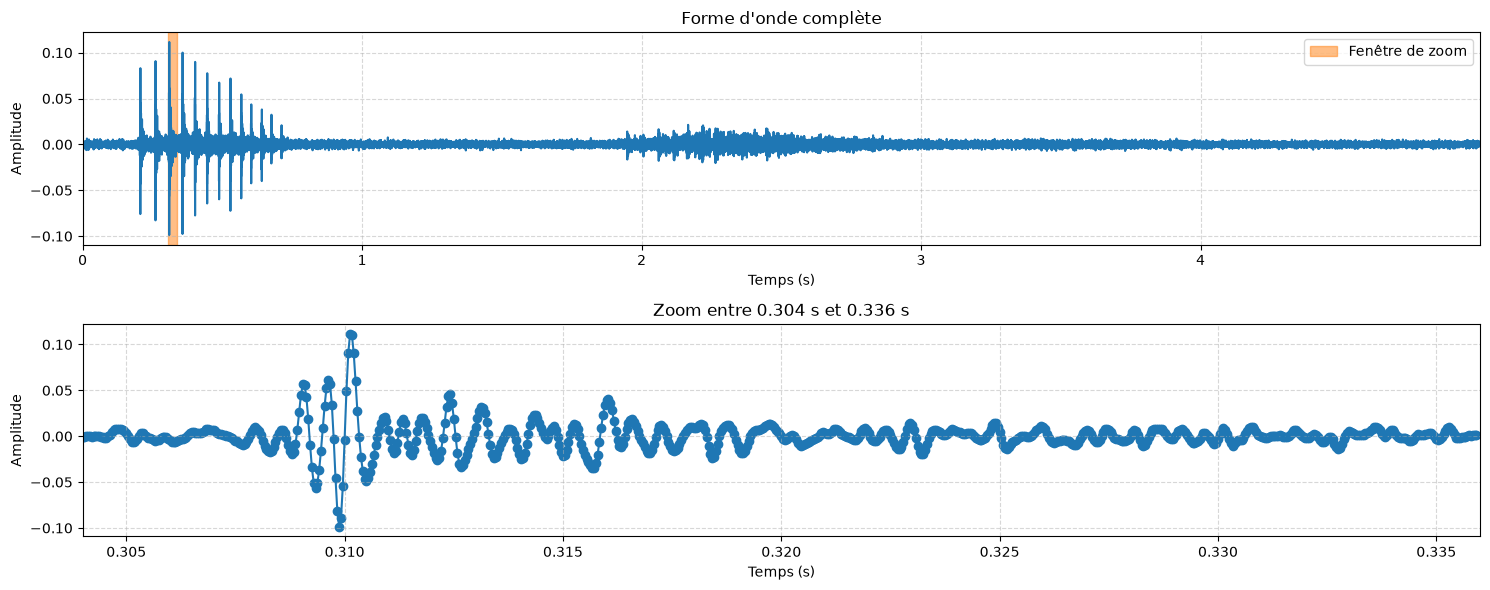

In [ ]:
# Affichage de la forme d'onde
t = np.arange(len(waveform)) / rate   # axe temporel en secondes

# Zoom sur une partie du signal (bornes en secondes)
start = 0.304
duration = 0.032
end = start + duration 

# Indices correspondant à la zone de zoom
i0 = int(start * rate)
i1 = int(end * rate)

fig, axes = plt.subplots(2, 1, figsize=(15, 6))

# Signal complet
axes[0].plot(t, waveform)
axes[0].axvspan(start, end, color="tab:orange", alpha=0.5, label="Fenêtre de zoom")  # zone zoomée
axes[0].set_xlabel("Temps (s)")
axes[0].set_xlim(0, t[-1])
axes[0].set_ylabel("Amplitude")
axes[0].set_title("Forme d'onde complète")
axes[0].grid(linestyle="--", alpha=0.5)
axes[0].legend()

# Zoom
axes[1].plot(t[i0:i1], waveform[i0:i1])
axes[1].scatter(t[i0:i1], waveform[i0:i1])
axes[1].set_xlim(start, end)
axes[1].set_xlabel("Temps (s)")
axes[1].set_ylabel("Amplitude")
axes[1].set_title(f"Zoom entre {start:.3f} s et {end:.3f} s")
axes[1].grid(linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

## 1.2 - Transformée de Fourier à court-terme (STFT)

Transformation de la forme d'onde en une matrice temps-fréquence $S \in \mathbb{R}^{F \times M}$.

Chaque colonne $m \in \llbracket 0, M-1 \rrbracket$ contient une représentation du contenu fréquentiel de la fenêtre audio $x_m$ suivante :

$$x_m[k] = x[mH + k]\; w[k], \qquad k \in \llbracket 0, W-1 \rrbracket$$

où $W$ est la taille de la fenêtre, $H$ est la *hop size* et $w : \llbracket 0, W-1\rrbracket \rightarrow [0, 1]$ est appelée fenêtre de Hann et définie par :
$ w[k] = \sin^2 \left( \frac{\pi k}{W - 1} \right)$ .

On calcule ensuite la transformée de Fourier discrète de $x_m$ avec une résolution de $n_\text{fft}$ :


$$\displaystyle X_m[f] = \sum_{k=0}^{W-1} x_m[n]\; e^{-2 i \pi f \frac{k}{n_{\text{fft}}}} 
\quad \in \mathbb{C},
\qquad f \in \llbracket 0, n_\text{fft}-1 \rrbracket$$

Finalement, on stocke dans la matrice le carré du module des $F=\frac{1}{2}n_\text{fft} + 1$ premiers coefficients de $X_m[f]$ (les suivants sont redondants, $X_m[n_\text{fft} - f] = \bar{X}_m[f]$).
 
$$S[f, m] = \left| X_m[f] \right|^2 \quad \in \mathbb{R}_+, \qquad f \in \llbracket 0, F-1 \rrbracket$$

In [ ]:
# Paramètres de la STFT

hop_ms = 16 # durée en ms
hop_length = int(hop_ms * rate / 1000) # durée en échantillons
win_length = 2 * hop_length # taille de la fenêtre audio
n_fft = 1024 # résolution de la fft

# Taille de la matrice STFT
F = n_fft // 2 + 1
n_columns = (waveform.shape[0] - win_length) // hop_length

print(f"n_window: {win_length}, hop_length: {hop_length}, n_fft: {n_fft}")
print(f"Taille de la matrice STFT: {F} x {n_columns}")

n_window: 768, hop_length: 384, n_fft: 1024
Taille de la matrice STFT: 513 x 310


Compléter ci-dessous le calcul de la colonne $m$ de $S$

In [ ]:
m = 19 # indice de la colonne à calculer

hann_window = np.hanning(win_length) # fenêtre de hanning

# Indices de début et de fin de la fenêtre m
start = ...
end = ...

audio_chunk = waveform[start:end]

# Multiplication par la fenêtre de hann
windowed_audio_chunk = ...

# Transformée de Fourier complexe
spectrum = np.fft.fft(windowed_audio_chunk, n_fft)

# Module carré (on garde pour l'instant tous les coefficients pour illustrer la symétrie)
power_spectrum = np.abs(spectrum) ** 2

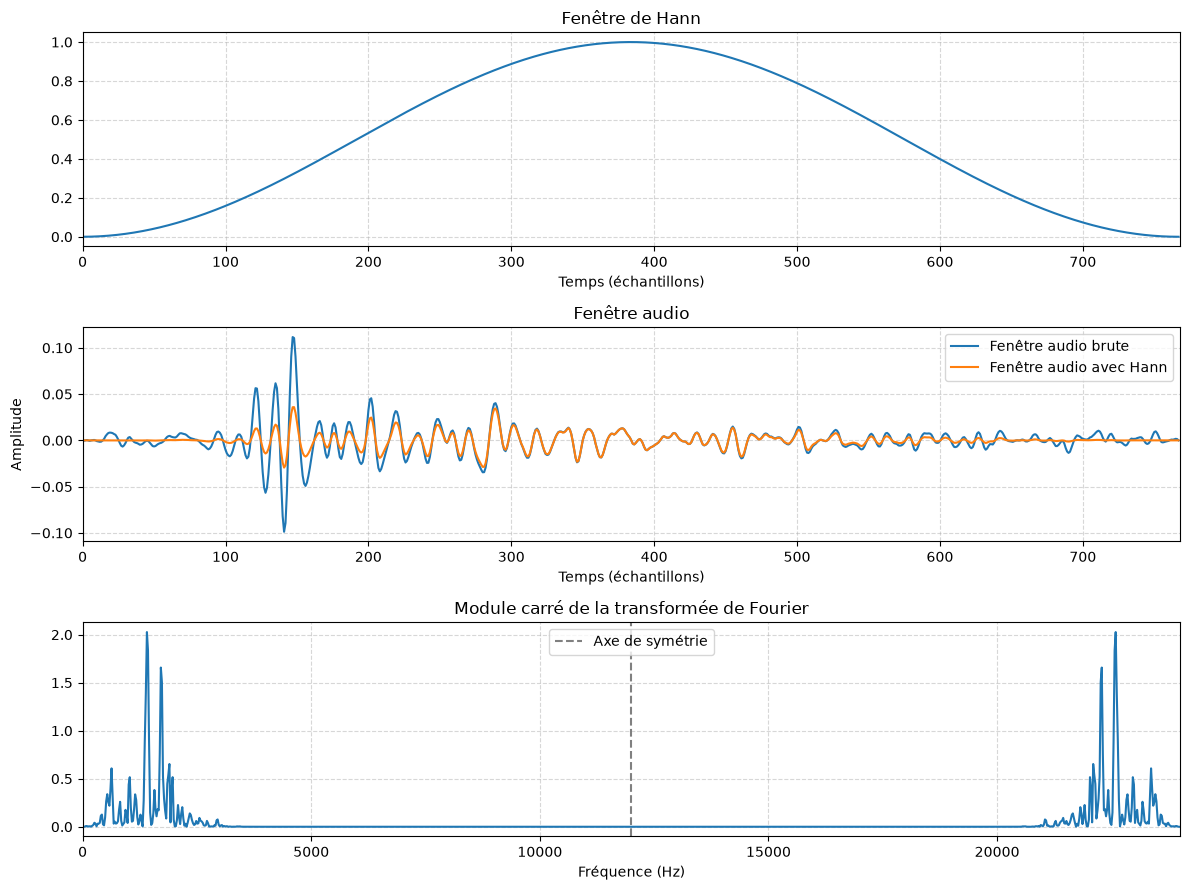

In [ ]:
# Affichage
fig, axes = plt.subplots(3, 1, figsize=(12, 9))
freq_axis = np.linspace(0, rate, n_fft, endpoint=False)

# Fenêtre de Hann
axes[0].plot(hann_window)
axes[0].set_xlim(0, win_length)
axes[0].set_xlabel("Temps (échantillons)")
axes[0].set_title("Fenêtre de Hann")
axes[0].grid(linestyle="--", alpha=0.5)

# Fenêtre audio
axes[1].plot(audio_chunk, label="Fenêtre audio brute")
axes[1].plot(windowed_audio_chunk, label="Fenêtre audio avec Hann")
axes[1].set_xlim(0, win_length)
axes[1].set_xlabel("Temps (échantillons)")
axes[1].set_ylabel("Amplitude")
axes[1].legend()
axes[1].set_title("Fenêtre audio")
axes[1].grid(linestyle="--", alpha=0.5)

# Spectre de puissance
axes[2].plot(freq_axis, power_spectrum)
axes[2].axvline(rate / 2, linestyle="--", color="grey", label="Axe de symétrie")
axes[2].set_xlim(0, rate)
axes[2].set_xlabel("Fréquence (Hz)")
axes[2].legend()
axes[2].set_title("Module carré de la transformée de Fourier")
axes[2].grid(linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

Compléter ci-dessous le calcul de matrice $S$ entière

In [ ]:
def compute_stft(waveform):
        
    stft = np.zeros((F, n_columns))

    for m in range(n_columns):
        start = ...
        end = ...
        
        audio_chunk = ...
        windowed_audio_chunk = ...

        spectrum = ...
        stft[:, m] = ...

    return stft

stft = compute_stft(waveform)

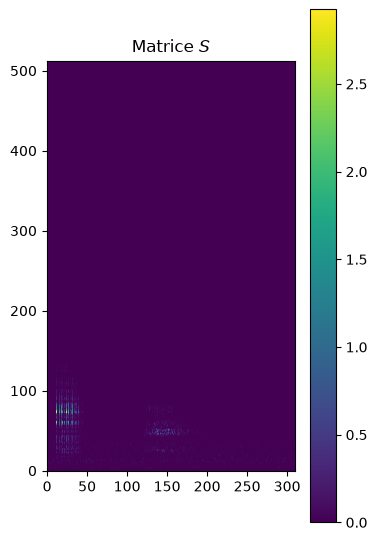

In [ ]:
# Affichage de la matrice
plt.matshow(stft, origin="lower")
plt.colorbar()
plt.gca().xaxis.tick_bottom() 
plt.title("Matrice $S$")
plt.show()

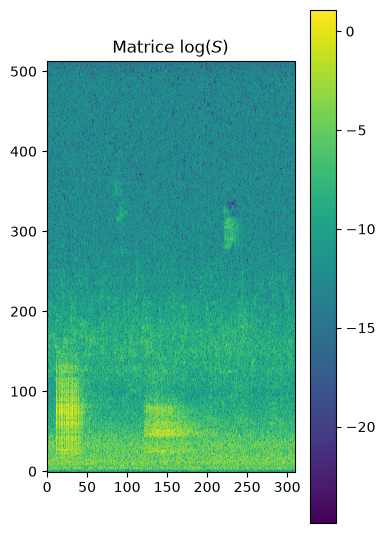

In [ ]:
# Compression d'amplitude (cf 1.4)
plt.matshow(np.log(stft), origin="lower")
plt.gca().xaxis.tick_bottom() 
plt.title("Matrice $\\log(S)$")
plt.colorbar()
plt.show()

## 1.3 - Échelle de Mel

L'échelle linéaire pour les fréquences n'est pas la plus adaptée.
On préfère utiliser l'échelle de Mel définie ci-dessous.

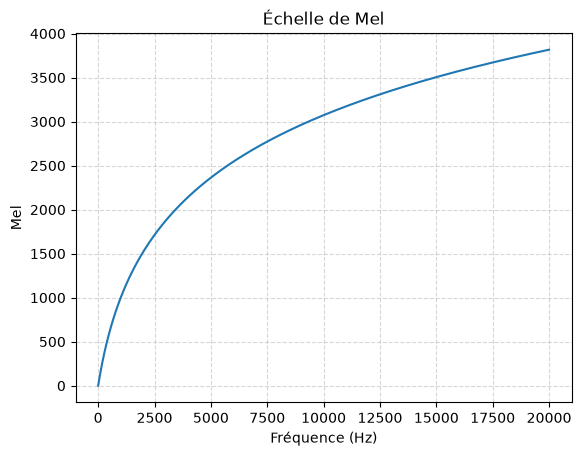

In [ ]:
def hz_to_mel(freq):
    return 2595.0 * np.log10(1.0 + (freq / 700.0))

freqs = np.linspace(0, 20000, 1000)
mels = hz_to_mel(freqs)

plt.plot(freqs, mels)
plt.title("Échelle de Mel")
plt.xlabel("Fréquence (Hz)")
plt.ylabel("Mel")
plt.grid(linestyle="--", alpha=0.5)
plt.show()

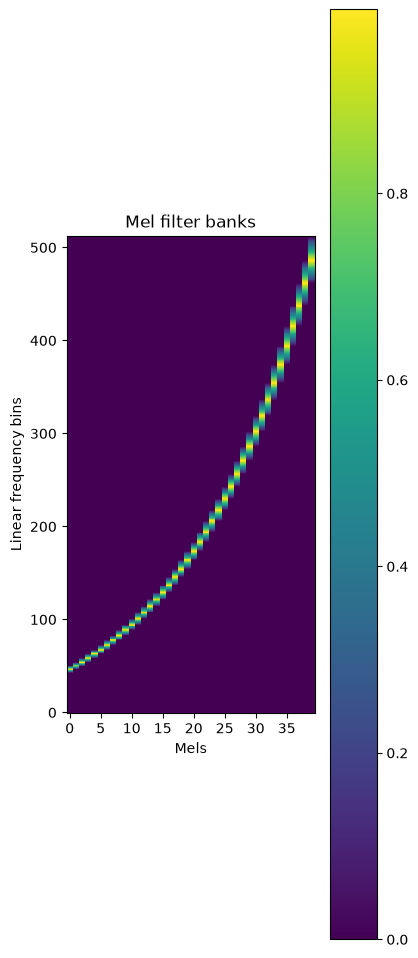

In [ ]:
n_mels = 40

f_min_mel = 1000
f_max_mel = 12000

mel_filters = torchaudio.functional.melscale_fbanks(F, f_min_mel, f_max_mel, 
                                                    n_mels, rate, mel_scale="htk")
mel_filters = mel_filters.numpy()

plt.matshow(mel_filters, origin="lower", aspect=0.15, interpolation='nearest')
plt.ylabel("Linear frequency bins")
plt.xlabel("Mels")
plt.gca().xaxis.tick_bottom() 
plt.title("Mel filter banks")
plt.colorbar()
plt.show()

In [ ]:
# Application des bancs de filtre

def compute_mel_spectrogram(waveform):

    stft = ...
    mel_spec = ...
    
    return mel_spec

mel_spec = compute_mel_spectrogram(waveform)

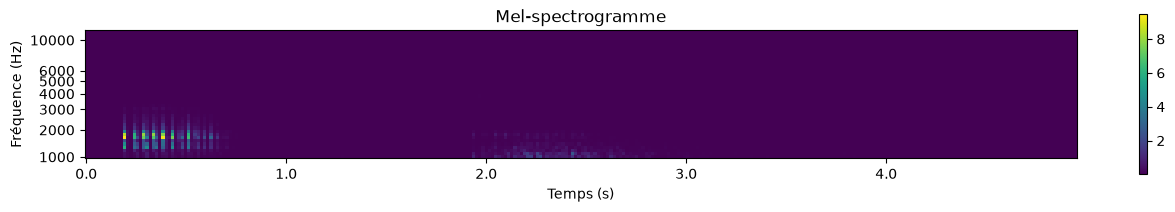

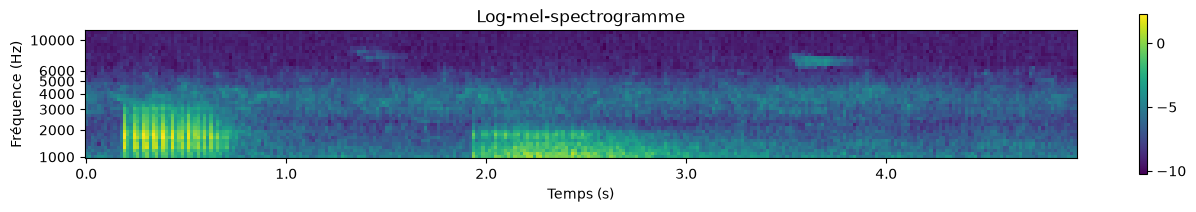

In [ ]:
# affichage des mel-spectrogrammes
plot_mel_spec(mel_spec, f_min_mel, f_max_mel, n_mels, 
              hop_length, waveform.shape[-1], rate,
              title="Mel-spectrogramme")

log_mel_spec = np.log(mel_spec)
plot_mel_spec(log_mel_spec, f_min_mel, f_max_mel, n_mels, 
              hop_length, waveform.shape[-1], rate,
              title="Log-mel-spectrogramme")

## 1.4 - Compression d'amplitude

À la place du log, on applique la fonction :
$x \mapsto \log(1 + \frac{x}{\varepsilon})$

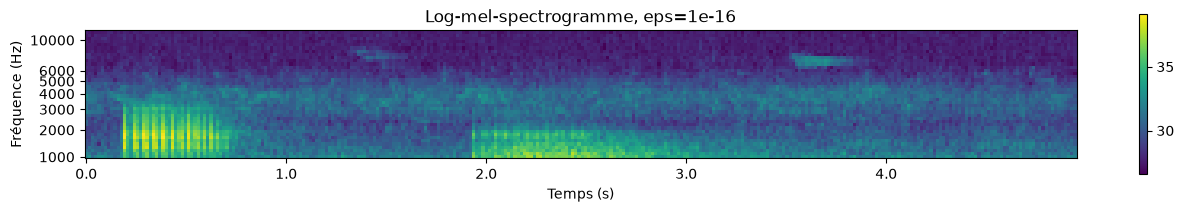

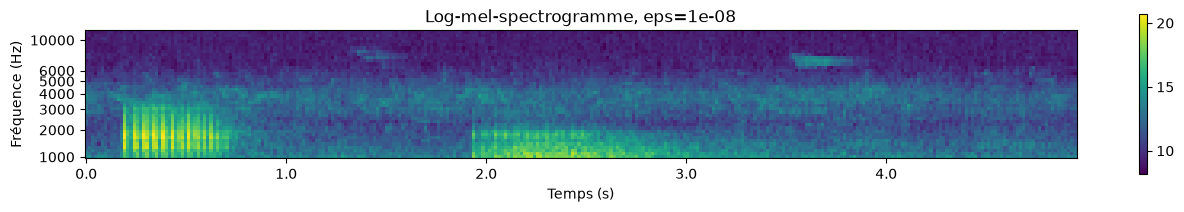

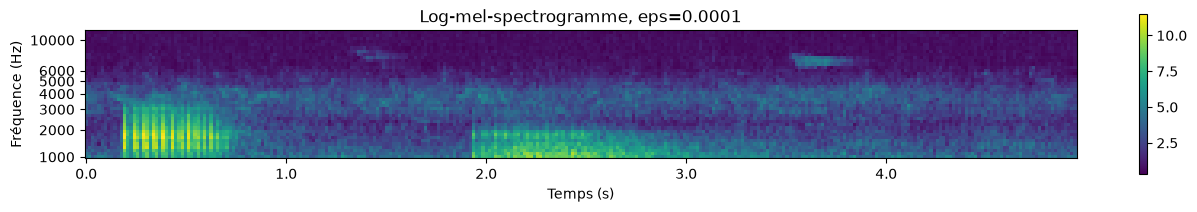

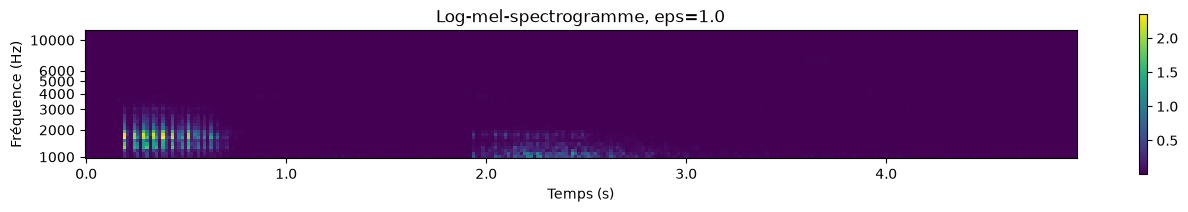

In [ ]:
# Visualisation du spectrogramme pour plusieurs valeurs de epsilon

for eps in [1e-16, 1e-8, 1e-4, 1e0]:
    
    log_transform = lambda x: np.log1p(x / eps)

    log_mel_spec = ...

    plot_mel_spec(log_mel_spec, f_min_mel, f_max_mel, n_mels, 
              hop_length, waveform.shape[-1], rate,
              title=f"Log-mel-spectrogramme, eps={eps}",
              aspect=1)

### Visualisation de l'effet sur les histogrammes des valeurs


In [ ]:
# Chargement de l'ensemble des fichiers exemples

examples_folder = "data/examples"
f_names = os.listdir(examples_folder)

mel_specs = []

for f_name in f_names:
    wav_path = os.path.join(examples_folder, f_name)
    waveform, rate = librosa.load(wav_path, sr=None)

    mel_spec = ...
    mel_specs.append(mel_spec.reshape(-1, *mel_spec.shape))

mel_specs = np.concatenate(mel_specs, axis=0)

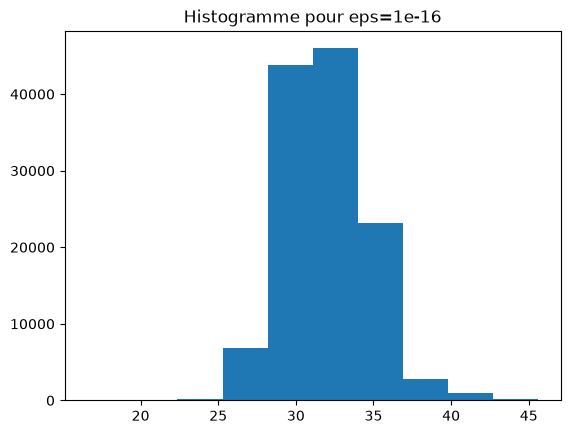

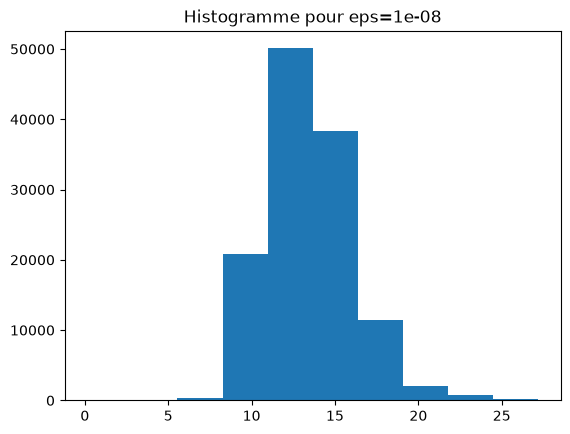

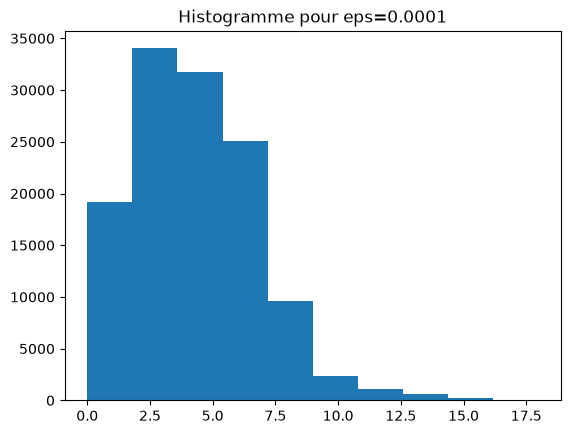

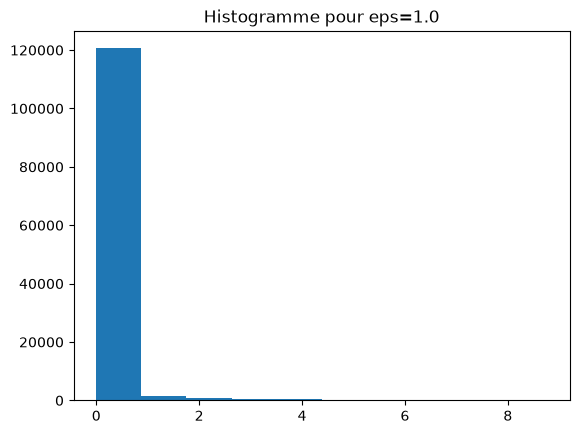

In [ ]:

for eps in [1e-16, 1e-8, 1e-4, 1e0]:
    
    log_transform = lambda x: np.log1p(x / eps)

    log_mel_specs = ...
    plt.hist(log_mel_specs.reshape(-1))
    plt.title(f"Histogramme pour eps={eps}")
    plt.show()